In [3]:
library(tidyverse)
library(rtracklayer)
library(pheatmap)
library(gridExtra)

── Attaching core tidyverse packages ──────────────────────── tidyverse 2.0.0 ──
✔ dplyr     1.1.4     ✔ readr     2.1.5
✔ forcats   1.0.0     ✔ stringr   1.5.1
✔ ggplot2   3.5.2     ✔ tibble    3.2.1
✔ lubridate 1.9.4     ✔ tidyr     1.3.1
✔ purrr     1.0.2     
── Conflicts ────────────────────────────────────────── tidyverse_conflicts() ──
✖ dplyr::filter() masks stats::filter()
✖ dplyr::lag()    masks stats::lag()
ℹ Use the conflicted package (<http://conflicted.r-lib.org/>) to force all conflicts to become errors
Loading required package: GenomicRanges

Loading required package: stats4

Loading required package: BiocGenerics


Attaching package: ‘BiocGenerics’


The following objects are masked from ‘package:lubridate’:

    intersect, setdiff, union


The following objects are masked from ‘package:dplyr’:

    combine, intersect, setdiff, union


The following objects are masked from ‘package:stats’:

    IQR, mad, sd, var, xtabs


The following objects are masked from ‘package:b

In [9]:
ifn_PRO <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/IFN_v_Veh_PROseq_cRE.tsv", sep='\t')
bafinh_ifn_PRO <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/BAFinh_IFN_v_IFN_PROseq_cRE.tsv", sep='\t')
dREG_veh <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/veh/veh.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
dREG_ifn <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/ifn/ifn.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
DAR_ifn <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_IFN_1h.tsv", sep='\t')
dREG_bafinh_ifn <- import("/mnt/disk/home/agulka/projects/PROseq_IFN/PROseq_GM12878_IFN/dreg/bafinh_ifn/bafinh_ifn.dREG.peak.full.bed.gz", format="BED", extraCols = c(dreg_score = "numeric", pvalue = "numeric", summit = "numeric"))
DAR_bafinh_ifn <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/DARs/GM12878_stimulus/DAR_BRM_IFN_1h.tsv", sep='\t')
counts <- read.delim("/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics/inputs/countmat/PROseq_eRNA/PROseq_cRE_counts.tsv", sep='\t')
log2_cpm <- apply(counts[,-1:-5],2,function(x) 1000000*x/sum(x)) %>% data.frame() %>% +1 %>% log2()
W        <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"
ens <- read.delim(file.path(W, "inputs/ENSEMBL/ensembl.canonical.prot-coding.transcript.tsv"))


In [10]:
genes <- GRanges(seqnames=paste0("chr",ens$Chromosome.scaffold.name), IRanges(start=ens$Transcript.start..bp., end=ens$Transcript.end..bp.))
genes

GRanges object with 19732 ranges and 0 metadata columns:
          seqnames            ranges strand
             <Rle>         <IRanges>  <Rle>
      [1]     chr1   3069203-3438621      *
      [2]     chr1   2403974-2412564      *
      [3]     chr1 10474950-10630758      *
      [4]     chr1   2476289-2505532      *
      [5]     chr1   9292894-9369532      *
      ...      ...               ...    ...
  [19728]     chrY   6246223-6249018      *
  [19729]     chrY 21880076-21894526      *
  [19730]     chrY 21903622-21918032      *
  [19731]     chrY 22168542-22182923      *
  [19732]     chrY 22403410-22417881      *
  -------
  seqinfo: 24 sequences from an unspecified genome; no seqlengths

In [11]:
annot_gr <- makeGRangesFromDataFrame(ifn_PRO)
ol_veh <- findOverlaps(annot_gr, dREG_veh)
ol_ifn <- findOverlaps(annot_gr, dREG_ifn)
ol_bafinh_ifn <- findOverlaps(annot_gr, dREG_bafinh_ifn)

aggregated <- data.frame(
    ifn_PRO[,2:5],
    PRO_lfc = ifn_PRO$log2FoldChange,
    PRO_bafinh_lfc=bafinh_ifn_PRO$log2FoldChange,
    ATAC_lfc = DAR_ifn$logFC,
    ATAC_bafinh_lfc=DAR_bafinh_ifn$logFC,
    PRO_change=ifn_PRO$change,
    ATAC_change=DAR_ifn$change,
    counts_veh = rowMeans(log2_cpm[,grepl("veh_veh", colnames(log2_cpm))]),
    counts_ifn = rowMeans(log2_cpm[,grepl("veh_IFN", colnames(log2_cpm))]),
    intragenic=countOverlaps(annot_gr, genes) > 0)

aggregated$dREG_veh_ol <- 0
aggregated$dREG_veh_ol[queryHits(ol_veh)] <- 1
aggregated$dREG_veh_score <- NA
aggregated$dREG_veh_score[queryHits(ol_veh)] <- dREG_veh$dreg_score[subjectHits(ol_veh)]

aggregated$dREG_ifn_ol <- 0
aggregated$dREG_ifn_ol[queryHits(ol_ifn)] <- 1
aggregated$dREG_ifn_score <- NA
aggregated$dREG_ifn_score[queryHits(ol_ifn)] <- dREG_ifn$dreg_score[subjectHits(ol_ifn)]

aggregated$dREG_bafinh_ifn_ol <- 0
aggregated$dREG_bafinh_ifn_ol[queryHits(ol_bafinh_ifn)] <- 1
aggregated$dREG_bafinh_ifn_score <- NA
aggregated$dREG_bafinh_ifn_score[queryHits(ol_bafinh_ifn)] <- dREG_bafinh_ifn$dreg_score[subjectHits(ol_bafinh_ifn)]


aggregated <- aggregated %>% 
                mutate(dREG_gain = (dREG_ifn_ol - dREG_veh_ol) == 1,
                       dREG_BAFindep=dREG_gain & dREG_bafinh_ifn_ol,
                       dREG_BAFdep=dREG_gain & !dREG_bafinh_ifn_ol)
head(aggregated)
ATAC_up <- which(aggregated$ATAC_change=="up")
order <- order(aggregated[ATAC_up,"ATAC_lfc"], decreasing=T)

,seqnames,start,end,type,PRO_lfc,PRO_bafinh_lfc,ATAC_lfc,ATAC_bafinh_lfc,PRO_change,ATAC_change,⋯,intragenic,dREG_veh_ol,dREG_veh_score,dREG_ifn_ol,dREG_ifn_score,dREG_bafinh_ifn_ol,dREG_bafinh_ifn_score,dREG_gain,dREG_BAFindep,dREG_BAFdep
,<chr>,<int>,<int>,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>,<chr>,⋯,<lgl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<lgl>,<lgl>,<lgl>
1,chr1,778361,779215,prom,-0.01913999,0.04149576,-0.02446069,0.09398630,ns,ns,⋯,FALSE,0,NA,0,NA,0,NA,FALSE,FALSE,FALSE
2,chr1,804416,805076,other_nonTSS,0.24278592,0.55040896,0.08425899,-1.36178421,ns,ns,⋯,FALSE,0,NA,0,NA,0,NA,FALSE,FALSE,FALSE
3,chr1,817194,817588,other_TSS,-0.17536599,0.32122337,0.17846326,-0.02361173,ns,ns,⋯,FALSE,0,NA,0,NA,0,NA,FALSE,FALSE,FALSE
4,chr1,826851,828112,prom,-0.02735810,-0.04578156,0.05268213,-0.60855152,ns,ns,⋯,FALSE,1,1.14644,1,1.185837,1,1.199609,FALSE,FALSE,FALSE
5,chr1,838326,838675,other_nonTSS,-0.21595812,-0.14412452,-0.12059058,-0.33093274,ns,ns,⋯,FALSE,0,NA,0,NA,0,NA,FALSE,FALSE,FALSE
6,chr1,857920,859154,other_TSS,-0.12918079,0.49729273,0.08583374,-0.23903205,ns,ns,⋯,FALSE,0,NA,0,NA,0,NA,FALSE,FALSE,FALSE


`geom_smooth()` using formula = 'y ~ x'
Warning message:
“Removed 10260 rows containing non-finite outside the scale range
(`stat_smooth()`).”
Warning message:
“Removed 10260 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 18 rows containing missing values or values outside the scale range
(`geom_point()`).”


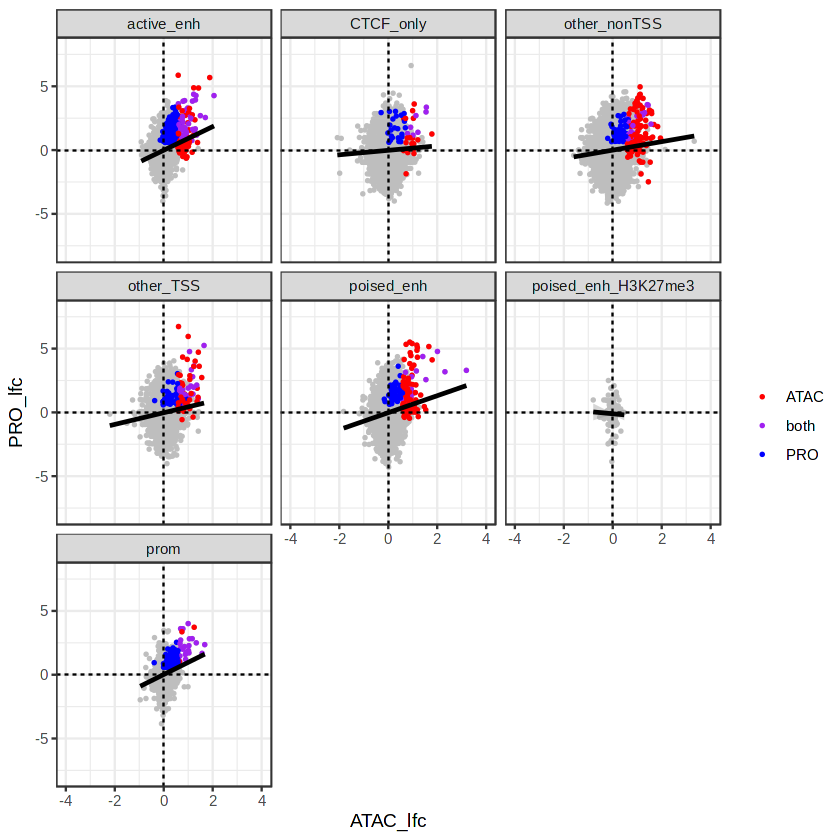

In [166]:
ggplot(aggregated, aes(x=ATAC_lfc, y=PRO_lfc, color=case_when(ATAC_change=="up" & PRO_change=="up" ~ "both",
                                  ATAC_change=="up" & PRO_change != "up" ~ "ATAC",
                                  ATAC_change != "up" & PRO_change == "up" ~ "PRO",
                                  TRUE ~ "other"))) +
    geom_point(color="grey", size=.5) + 
    geom_point(data=aggregated[which(aggregated$ATAC_change=="up" | aggregated$PRO_change=="up"),],, size=.5) +
    geom_smooth(method=lm, color="black") +
    geom_hline(yintercept=0, linetype=2) + geom_vline(xintercept=0, linetype=2) +
    scale_color_manual(values=c("other"="grey", "both"="purple", "ATAC"="red", "PRO"="blue"), name="")+
    xlim(-4,4) + ylim(-8,8) +
    theme_bw() +
    facet_wrap(~type)

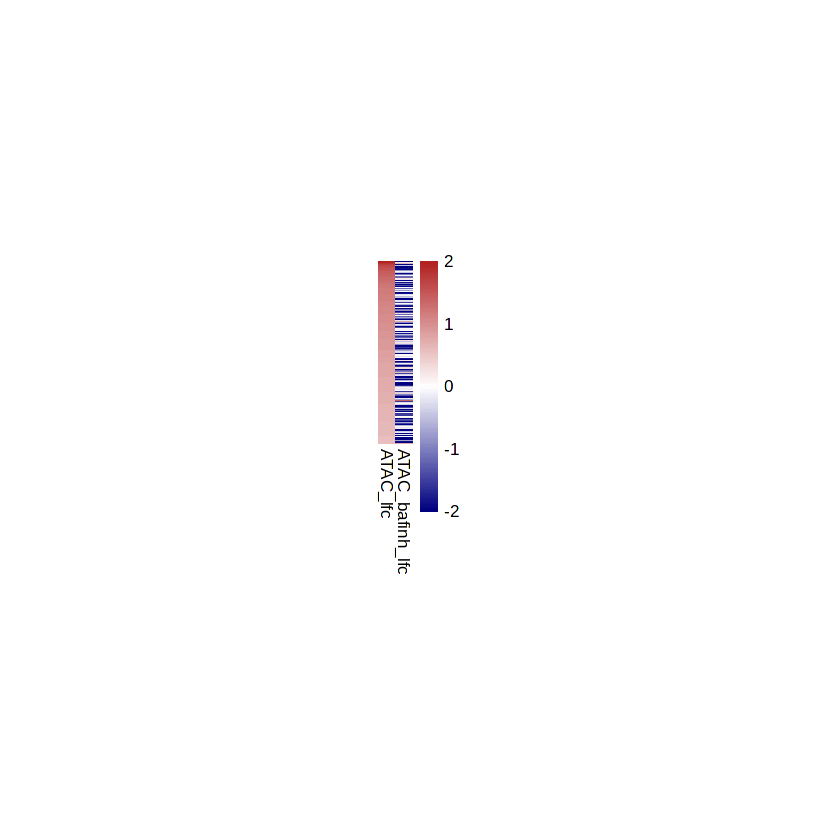

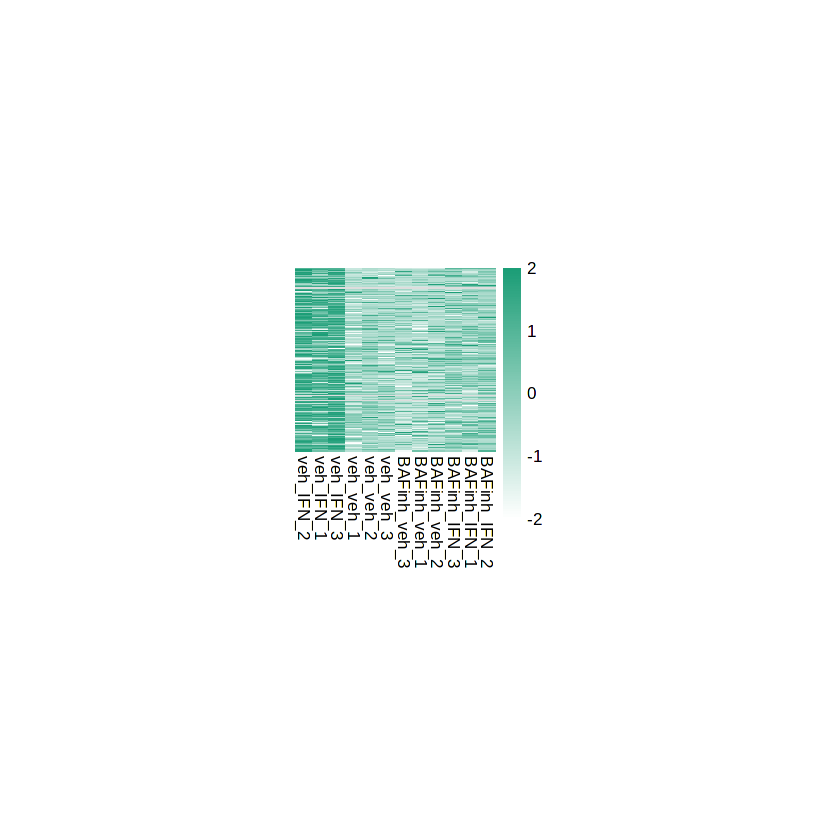

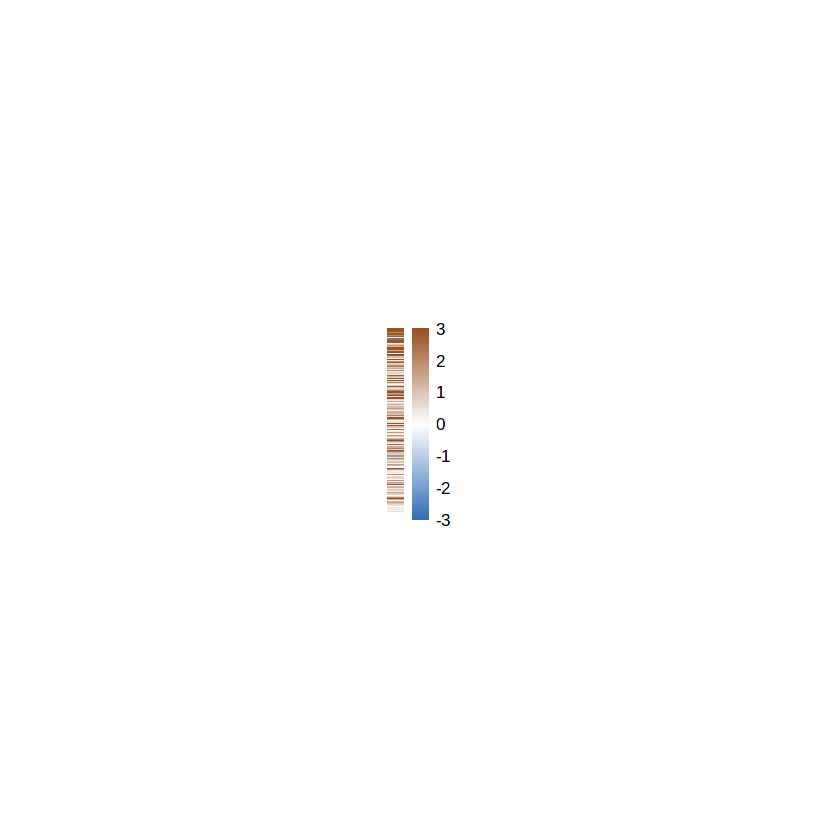

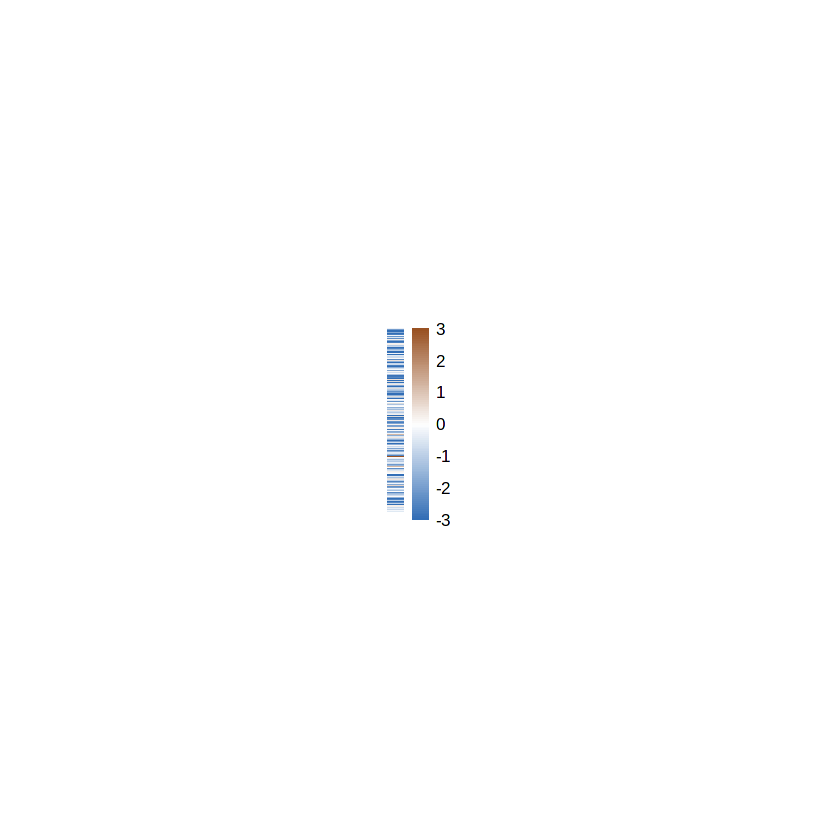

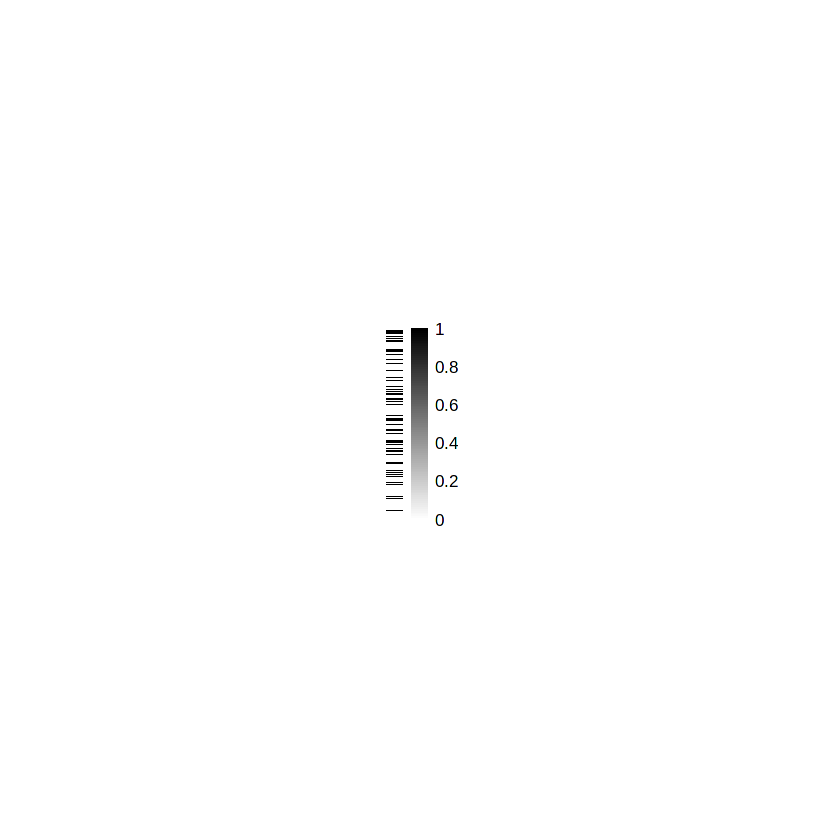

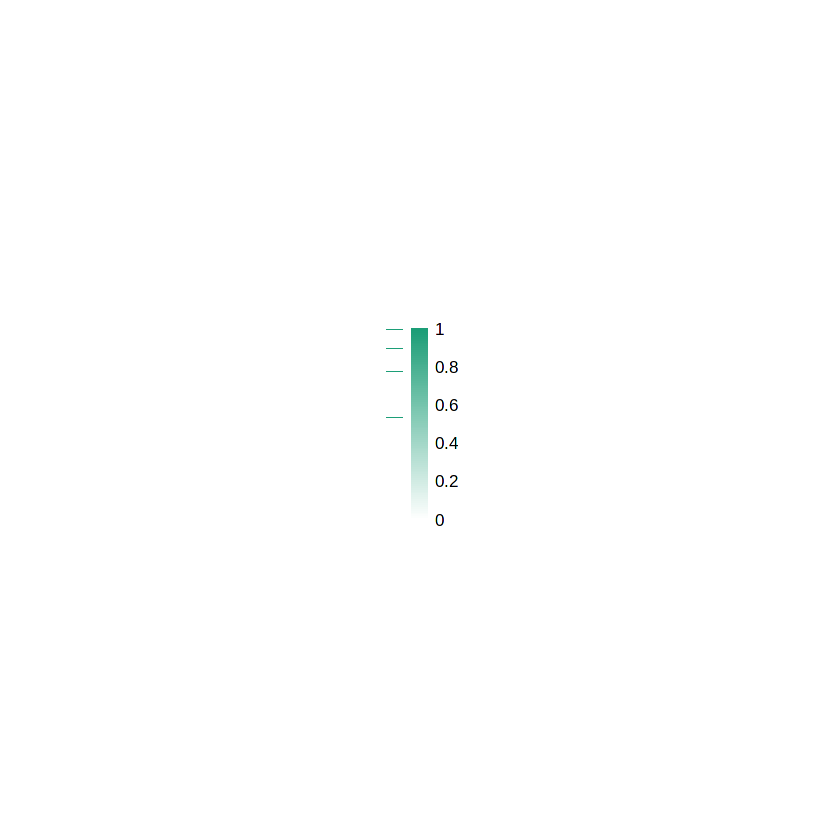

pdf 
  2

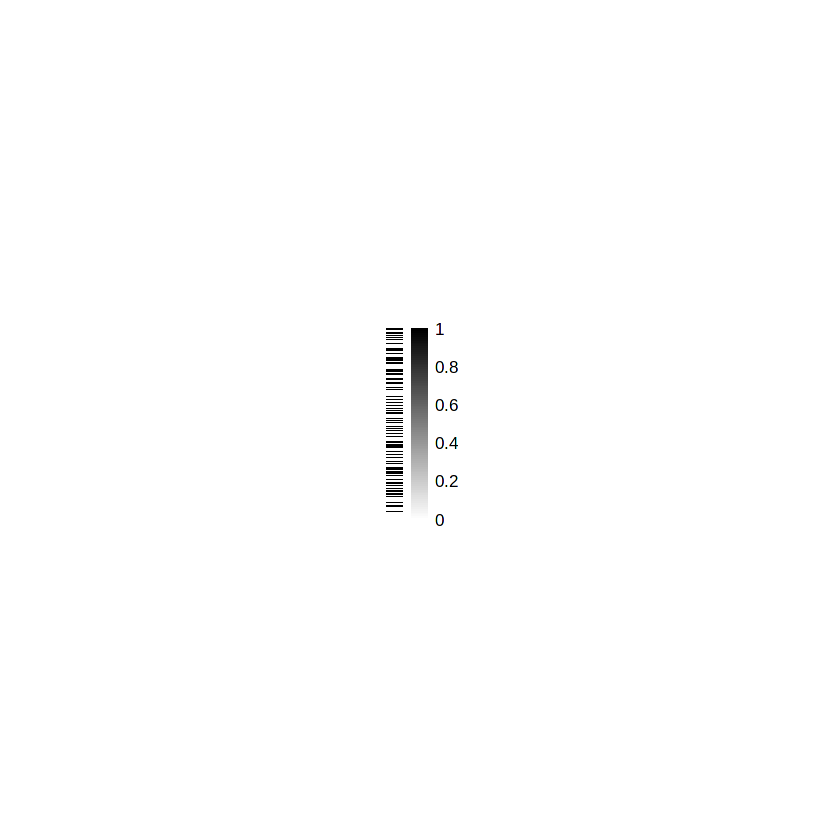

In [347]:
ATAC_up <- which(aggregated$ATAC_change=="up" )
order <- order(aggregated[ATAC_up,"ATAC_lfc"], decreasing=T)

p1 <- pheatmap(aggregated[ATAC_up,7:8][order,], 
         cluster_rows=F, 
         cluster_cols=F,
         col=colorRampPalette(colors=c("navy", "white", "firebrick"))(100),
         breaks=seq(-2,2,length.out=101), cellwidth=10, cellheight=.2, show_rownames=F)

p2 <- pheatmap(log2_cpm[ATAC_up,][order,], 
         cluster_rows=F, 
         cluster_cols=T,
         col=colorRampPalette(colors=c("white", "#1c9e77"))(100),
         breaks=seq(-2,2,length.out=101),
         cellwidth=10, cellheight=.2, 
         show_rownames=F,
         treeheight_col=0, scale="row")

p3 <- pheatmap(as.numeric(aggregated[ATAC_up,"PRO_lfc"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         breaks=seq(-3,3,length.out=101),
         colorRampPalette(colors=c("#326eb6","white", "#995223"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)


p4 <- pheatmap(as.numeric(aggregated[ATAC_up,"PRO_bafinh_lfc"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         breaks=seq(-3,3,length.out=101),
         colorRampPalette(colors=c("#326eb6","white", "#995223"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)


p5 <- pheatmap(as.numeric(aggregated[ATAC_up,"dREG_BAFdep"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         #colorRampPalette(colors=c("white", "#aaaaaa", "#1c9e77"))(100),
         colorRampPalette(colors=c("white", "black"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)

p6 <- pheatmap(as.numeric(aggregated[ATAC_up,"dREG_BAFindep"][order]), 
         cluster_rows=F, 
         cluster_cols=F,
         #colorRampPalette(colors=c("white", "#aaaaaa", "#1c9e77"))(100),
         colorRampPalette(colors=c("white", "#1c9e77"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)

p7 <- pheatmap(as.numeric(a$inside[order]), 
         cluster_rows=F, 
         cluster_cols=F,
         #colorRampPalette(colors=c("white", "#aaaaaa", "#1c9e77"))(100),
         colorRampPalette(colors=c("white", "black"))(100),
         cellwidth=10, cellheight=.2, show_rownames=F)

pdf("test.pdf", width=8)
grid.arrange(p1$gtable, p2$gtable, p3$gtable, p4$gtable, p5$gtable, p6$gtable,p7$gtable, nrow=1)
dev.off()

In [349]:
a %>% group_by(type,inside) %>% summarize(n())

`summarise()` has grouped output by 'type'. You can override using the
`.groups` argument.


type,inside,n()
<chr>,<lgl>,<int>
CTCF_only,FALSE,15
CTCF_only,TRUE,11
active_enh,FALSE,71
active_enh,TRUE,75
other_TSS,FALSE,44
other_TSS,TRUE,29
other_nonTSS,FALSE,93
other_nonTSS,TRUE,67
poised_enh,FALSE,76


In [12]:
GENE_CPM <- 1   # veh_IFN CPM at or above which a host gene counts as transcribed
W        <- "/mnt/disk/home/agulka/manuscripts/BAF_stimulus_CellGenomics"
ens <- read.delim(file.path(W, "inputs/ENSEMBL/ensembl.canonical.prot-coding.transcript.tsv"))
deg <- read.delim(file.path(W, "inputs/DEGs/GM12878/BAFinh_stimulus/PROseq/PRO_DEGs_IFN_Veh.tsv"))
cnt <- read.delim(file.path(W, "inputs/DEGs/GM12878/BAFinh_stimulus/PROseq/PRO_counts_genes.tsv"))

cpm  <- sweep(as.matrix(cnt), 2, colSums(cnt), "/") * 1e6
vIFN <- rowMeans(cpm[, c("veh_IFN_1", "veh_IFN_2", "veh_IFN_3")])
txn  <- deg$ENSEMBL_ID[vIFN >= GENE_CPM]

gr_txn <- GRanges(paste0("chr", ens$Chromosome.scaffold.name),
                  IRanges(ens$Transcript.start..bp., ens$Transcript.end..bp.))[
                  ens$Gene.stable.ID %in% txn]

a <- aggregated[aggregated$ATAC_change == "up", ]
a$inside <- overlapsAny(GRanges(a$seqnames, IRanges(a$start, a$end)), gr_txn)
a$gained <- a$dREG_veh_ol == 0 & a$dREG_ifn_ol == 1

In [ ]:
a$counts_ifn

In [23]:
a %>% group_by(dREG_ifn_ol, inside) %>%
    filter(!is.na(PRO_lfc)) %>%
    summarize(mean(counts_veh), mean(counts_ifn), mean(PRO_lfc))

`summarise()` has grouped output by 'dREG_ifn_ol'. You can override using the
`.groups` argument.


dREG_ifn_ol,inside,mean(counts_veh),mean(counts_ifn),mean(PRO_lfc)
<dbl>,<lgl>,<dbl>,<dbl>,<dbl>
0,FALSE,0.6250102,0.9097034,1.2053882
0,TRUE,1.4058847,1.9074807,0.7995664
1,FALSE,0.9584419,1.9104108,2.3137324
1,TRUE,1.6677217,2.6293764,1.6040158


In [24]:
aggregated$inside <- overlapsAny(GRanges(aggregated$seqnames, IRanges(aggregated$start, aggregated$end)), gr_txn)


In [36]:
bed1 <- aggregated %>% 
    filter(grepl("active_enh", type)) %>%
    filter(inside==TRUE) %>% 
    filter(dREG_veh_ol==TRUE) %>%
    select(seqnames,start,end)

bed2 <- aggregated %>% 
    filter(grepl("active_enh", type)) %>%
    filter(inside==TRUE) %>% 
    filter(dREG_veh_ol==FALSE) %>%
    select(seqnames,start,end)

bed3 <- aggregated %>% 
    filter(grepl("active_enh", type)) %>%
    filter(inside==FALSE) %>% 
    filter(dREG_veh_ol==TRUE) %>%
    select(seqnames, start, end)

bed4 <- aggregated %>% 
    filter(grepl("active_enh", type)) %>%
    filter(inside==FALSE) %>% 
    filter(dREG_veh_ol==FALSE) %>%
    select(seqnames, start, end)

In [38]:
write.table(bed1, "active_inGene_dREG.bed", col.names=F, row.names=F, quote=F, sep='\t')
write.table(bed2, "active_inGene_nodREG.bed", col.names=F, row.names=F, quote=F, sep='\t')
write.table(bed3, "active_NotinGene_dREG.bed", col.names=F, row.names=F, quote=F, sep='\t')
write.table(bed4, "active_NotinGene_nodREG.bed", col.names=F, row.names=F, quote=F, sep='\t')